In [8]:
import pandas as pd 
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

# US15 - Statistical Analysis of Railway Station Profits

## Objectives

The main objective of this user story (US15) is to perform a **statistical analysis** of the annual profits of a user-specified railway station. The analysis includes:

- Generating a table with key descriptive statistics: **mean**, **standard deviation**, **median**, and **mode** of the annual profits.
- Identifying **outlier** profits that outline from typical values.
- Determining the **most profitable year** and the **least profitable year**.

This statistical analysis provides insight into the financial performance of the stations, supporting better strategic decisions in the simulation of the railway network.

---

## Theoretical Concepts

- **Mean**: The arithmetic mean is the sum of all annual profits divided by the number of years. Measures average profit.

- **Standard Deviation**: This measures how the profits are spread out around the mean. A higher standard deviation indicates greater variability.

- **Median**: The median is the middle value of the profits when ordered. It is less sensitive to extreme values.

- **Mode**: The most frequently occurring profit value among the recorded years.

- **Outlier Detection (IQR Method)**:
  - The first quartile ($Q_1$) is the 25th percentile; the third quartile ($Q_3$) is the 75th percentile.
  - The interquartile range is calculated as: $IQR = Q_3 - Q_1$.
  - Profits are considered outliers if they are below $Q_1 - 1.5 \times IQR$ or above $Q_3 + 1.5 \times IQR$.

- **Most and Least Profitable Years**: These are identified by locating the maximum and minimum annual profits in the dataset, respectively.

---

## Methodology

The methodology applied to fulfill US15 involved:

1. Loading the station data from a CSV file using Python (`pandas` library).
2. Calculate the annual profit as (`Revenues - Expenses`).
3. Filtering data by the user-specified station.
4. Grouping profits by year and calculating the sum for each year.
5. Calculating the mean, standard deviation, median, and mode of the annual profits.
6. Detecting outliers using the Interquartile Range (IQR) method.
7. Identifying the years with the maximum and minimum profits.
---

In [4]:
df = pd.read_csv('Stations_Data.csv', sep=';', decimal=',') # df = dataFrame;
df['Profit'] = df['Revenues'] - df['Expenses']  # Criar colunas para o df

station_name = input("Enter the station name: ")

station_data = df[df['Station'] == station_name]

if station_data.empty:
    print(f"No data found in: {station_name}")
else:
    annual_profit = station_data.groupby('Year')['Profit'].sum().reset_index()
    
    mean_profit = annual_profit['Profit'].mean()
    std_dev_profit = annual_profit['Profit'].std()
    median_profit = annual_profit['Profit'].median()
    mode_result = annual_profit['Profit'].mode()
    mode_profit = mode_result[0] if not mode_result.empty else 'No mode'
    
    Q1 = annual_profit['Profit'].quantile(0.25)
    Q3 = annual_profit['Profit'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = annual_profit[(annual_profit['Profit'] < lower_bound) | (annual_profit['Profit'] > upper_bound)]
    
    max_profit_year = annual_profit.loc[annual_profit['Profit'].idxmax()]
    min_profit_year = annual_profit.loc[annual_profit['Profit'].idxmin()]
    
    stats_table = pd.DataFrame({
        'Statistic': ['Mean', 'Standard Deviation', 'Median', 'Mode'],
        'Value': [mean_profit, std_dev_profit, median_profit, mode_profit]
    })
    
    print("\nDescriptive Statistics:")
    print(stats_table.to_markdown(index=False))
    
    print("\nOutlier Years:")
if not outliers.empty:
    print(outliers.to_markdown(index=False))
else:
    print("No outliers detected")

print(f"\nMost Profitable Year: {max_profit_year['Year']:.0f} (Profit: {max_profit_year['Profit']:.2f})")
print(f"Least Profitable Year: {min_profit_year['Year']:.0f} (Profit: {min_profit_year['Profit']:.2f})")

Enter the station name:  Frankfurt



Descriptive Statistics:
| Statistic          |    Value |
|:-------------------|---------:|
| Mean               |  668.653 |
| Standard Deviation |  580.848 |
| Median             |  544.33  |
| Mode               | -236.28  |

Outlier Years:
|   Year |   Profit |
|-------:|---------:|
|   2018 |  1635.64 |
|   2022 |  -236.28 |
|   2024 |  1660.41 |

Most Profitable Year: 2024 (Profit: 1660.41)
Least Profitable Year: 2022 (Profit: -236.28)


# US15 - Result Interpretation and Analysis

## Analysis and Interpretation of Results

The statistical analysis carried out for US15 focused on evaluating the annual profit of a user-specified railway station. The analysis involved calculating the mean, standard deviation, median, and mode of yearly profits, identifying potential outliers, and highlighting the most and least profitable years.

For example, in the case of **Frankfurt Station**, the analysis revealed:

- A mean profit of approximately €668.65
- A standard deviation of €580.85, indicating significant yearly variation
- A median of €544.33, close to the mean but slightly lower, suggesting a few high-profit years skewed the average
- A mode of €-236.28, which corresponds to a notably unprofitable year
- Outlier years included 2018 and 2024 with high profits (above €1600), and 2022 with a significantly negative result

Factors such as volume of transported goods, passenger traffic, and operational costs directly affect station profitability.

---

## Extrapolation to the Project Context

In the broader scope of the Integrative Project, these results offer insights for the strategic management of a simulated railway network. Specifically, they enable:

1. **Strategic Resource Allocation:** Stations with consistently high profits may be prioritized for upgrades (e.g., terminals, improved services, increased capacity).

2. **Risk Assessment:** Identifying years with poor or volatile performance can inform maintenance planning, marketing strategies, or route adjustments to stabilize revenue.

3. **Scenario-Based Planning:** Outlier years may correspond to events in the simulation (e.g., demand spikes due to events, technological upgrades). Understanding these trends helps design more realistic scenarios.

4. **Station Classification:** Over time, stations can be classified as high-risk, high-profit, or low-value, enabling data-driven decisions within the simulation engine.

---

This analysis provides players and editors in the simulation with valuable knowledge to improve the efficiency and profitability of their rail networks. It supports a data-driven approach to gameplay, planning, and problem-solving in line with the objectives outlined in the PI project framework.


# US16 - Comparative Analysis of Passenger Arrivals

## Objectives

The main objective of this user story (US16) is to perform a **comparative analysis** of the passenger arrivals across all railway stations.  
This goal is achieved through the creation of a **boxplot** for each station, which helps in:

- Visualization of the distribution of passenger arrivals per station.
- Identifying variations and anomalies in passenger traffic.
- Facilitating the detection of stations with significantly higher or lower passenger volumes compared to others.

This analysis helps to understand traffic patterns, supporting strategic decisions such as investments in station upgrades, scheduling, or maintenance prioritization.

---

## Theoretical Concepts

- **Boxplot:** A graphical summary of data distribution based on five-number summaries: minimum, first quartile (Q1), median (Q2), third quartile (Q3), and maximum. It highlights the central tendency and variability.

- **Median:** The middle value of the data when sorted, indicating the typical passenger volume at a station.

- **Interquartile Range (IQR):** The range between the first quartile (25%) and the third quartile (75%). It measures the spread of the middle 50% of the data.

- **Outliers:** Points that fall below  
  $Q_1 - 1.5 \times IQR$  
  or above  
  $Q_3 + 1.5 \times IQR$.  
  In the boxplot, these are represented as small circles outside the whiskers, indicating anomalous years of passenger flow.

---

## Methodology

The methodology followed to accomplish US16 consisted of:

1. Loading the station data from a CSV file using `pandas`.
2. Detecting and confirming the correct column representing the number of arriving passengers.
3. Converting the passenger column to a numeric data type to avoid issues.
4. Grouping the passenger data by station.
5. Creating a boxplot where:
   - Each box represents the distribution of passenger arrivals at a specific station.
   - The y-axis shows the number of passengers using an appropriate scale for better readability.
   - Outliers (anomalous values) are indicated as separate points.

---

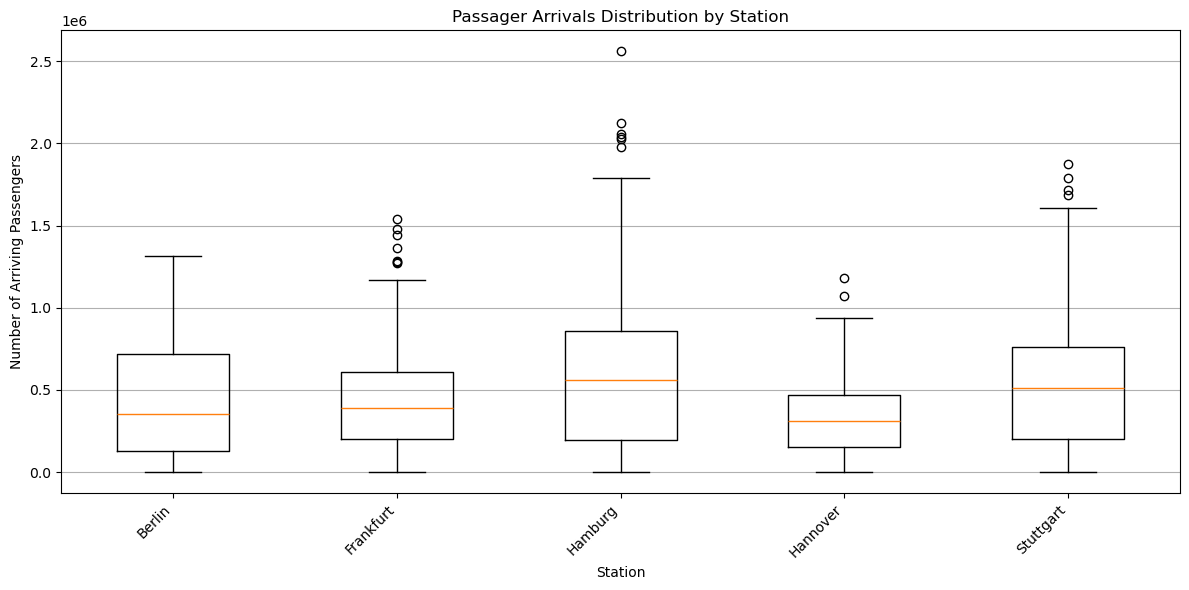

In [9]:
df = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

for col in ['ArrivingPassengers', 'PassengerArrivals', 'Passengers', 'Passenger Arrivals']:
    if col in df.columns:
        passenger_col = col
        break

df[passenger_col] = pd.to_numeric(df[passenger_col], errors='coerce')

stations = sorted(df['Station'].unique())
data = [
    df.loc[df['Station'] == station, passenger_col].dropna().values
    for station in stations
]

plt.figure(figsize=(12, 6))
plt.boxplot(data, tick_labels=stations, showfliers=True)
plt.title('Passager Arrivals Distribution by Station')
plt.xlabel('Station')
plt.ylabel('Number of Arriving Passengers')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# US16 - Result Interpretation and Extrapolation

## Analysis and Interpretation of Results

The analysis developed under US16 aimed to compare the number of arriving passengers across all stations using historical data. This was achieved through the creation of a boxplot for each station, enabling the visualization of distribution patterns such as: median values, variability, and outliers.

From the dataset provided (`Stations_Data.csv`), the following insights were observed:

- **Hamburg** and **Stuttgart** showed the highest medians in passenger arrivals (e.g., 560,178.5 and 511,673 passengers), suggesting high-traffic.
- **Hannover** had the lowest median (309,050), indicating comparatively lower traffic.
- Outliers identified in the boxplots (represented as small circles above or below the whiskers) reveal years with unusually high or low passenger numbers, which might relate to special events such as major upgrades, disruptions, or regional events.
- The use of proper y-axis scaling (0 to 2,500,000 passengers in 500k steps, presented in a smaller scale) provided meaningful comparisons between stations and clarified differences that would otherwise be hidden due to inconsistent units or visual distortion.

These statistical representations make it easy to distinguish stations with stable flow patterns from those with inconsistent or extreme fluctuations.

---

## Extrapolation to the Project Context

In the context of the Integrative Project (PI), the results obtained from US16 are directly applicable to strategic planning and gameplay elements of the railway network simulation:

1. **Passenger-Centric Planning:** Stations with high and consistent passenger volume (e.g., Hamburg) can be prioritized for terminal-level upgrades, additional train routes, or auxiliary services such as post offices or hotels.

2. **Capacity and Scheduling Optimization:** Understanding the variability in passenger volume helps in optimizing train frequency and scheduling to reduce overcapacity or underuse.

3. **Economic Impact Estimation:** Since passengers contribute to station revenue, the volume of arrivals is linked to the performance analyzed in US15. Combining both allows us to understand the relationship between profit and passenger volume.

4. **Visual Insights for Game Balance:** The use of boxplots within the interface can serve as an internal analysis tool for the player or designer to rebalance gameplay.

---

Thus, this analysis supports more realistic and data-informed decision-making within the simulation, reinforcing the PI’s goal of developing a system that mimics the economic and operational complexity of railway networks.


# US17 - Cargo Analysis by Station and Type

## Objectives

The main objective of this user story (US17) is to perform a **statistical analysis** of the cargo arriving at a specific station based on a user-selected cargo type. The goal is to understand the distribution of that cargo type over time using a histogram. Specifically, this analysis aims to:

- Allow the user to select both the **station** and the **cargo type**.
- Generate a **histogram** to visualize the distribution of that cargo type's delivery values.
- Identify trends, variations, and possible anomalies in the volume of cargo received.

This analysis helps players interpret supply chain behaviors in the railway network simulation and supports informed decision-making regarding logistics and cargo prioritization.

---

## Theoretical Concepts

- **Histogram:** A graphical representation of the distribution of numerical data. It divides the range of data into intervals (bins) and counts how many values fall into each interval.

- **Kernel Density Estimation (KDE):** Optional overlay in the histogram that provides a curve approximating the data distribution, helping to identify tendencies.

- **Data Preprocessing:** The selected cargo column is converted to numeric format to ensure compatibility with histogram generation and to handle any inconsistent or missing entries.

---

## Methodology

The methodology applied to fulfill US17 involved the following steps:

1. Loading the complete station dataset from the CSV file using Python's `pandas` library.
2. Prompting the user to input a valid **station name** and **cargo type**.
3. Filtering the dataset based on the selected station.
4. Converting the cargo column to numeric format using `pd.to_numeric()` to handle any missing or invalid values.
5. Plotting the histogram using the `seaborn.histplot()` function with optional KDE enabled and colored styling.
6. Adjusting the figure layout, titles, and axis labels for clarity and presentation quality.

---

Enter the station name:  Berlin


Available cargo types: ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']


Enter the cargo type to analyze:  Iron


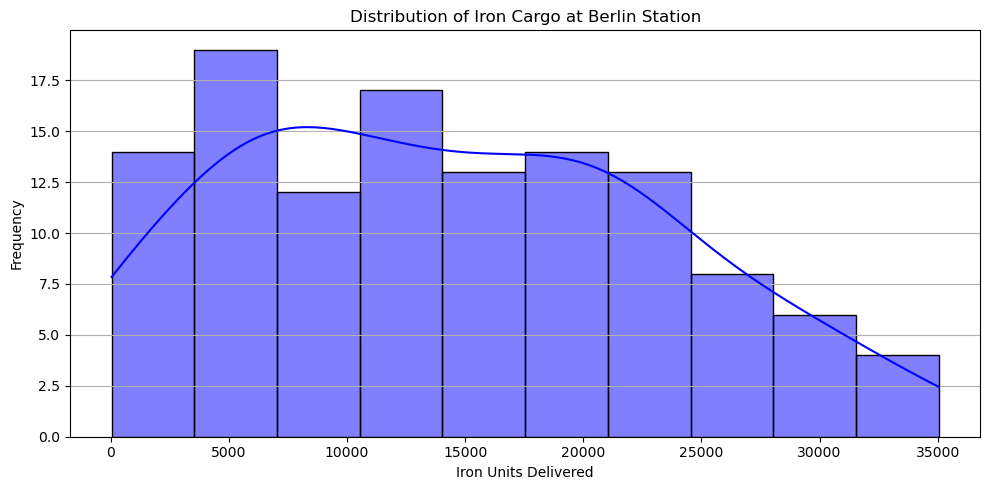

In [6]:
df = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

cargo_columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']

station_name = input("Enter the station name: ")
if station_name not in df['Station'].unique():
    print(f"No station found for: {station_name}")
else:
    print("Available cargo types:", cargo_columns)
    cargo_type = input("Enter the cargo type to analyze: ")
    if cargo_type not in cargo_columns:
        print(f"Invalid cargo type. Choose from: {cargo_columns}")
    else:
        station_data = df[df['Station'] == station_name].copy()
        station_data[cargo_type] = pd.to_numeric(station_data[cargo_type], errors='coerce')

        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=station_data,
            x=cargo_type,
            bins=10,
            kde=True, # ativar ou desativar a linha no grafico
            color='blue',
            edgecolor='black'
        )

        plt.title(f'Distribution of {cargo_type} Cargo at {station_name} Station')
        plt.xlabel(f'{cargo_type} Units Delivered')
        plt.ylabel('Frequency')
        plt.grid(axis='y')
        plt.tight_layout()
        plt.show()

# US17 - Result Interpretation and Analysis

## Analysis and Interpretation of Results

The statistical analysis for US17 focused on the evaluation of cargo arrival patterns at a specific station for a selected cargo type. By allowing the user to specify both parameters, the system generated a histogram to visualize how frequently different volumes of that cargo type were delivered over the years.

For example, in the case of **Berlin Station** analyzing **Iron** deliveries, the histogram showed:

- A right-skewed distribution, indicating that small-to-moderate deliveries were most common.
- One or two bars at the higher end of the scale, suggesting occasional large shipments — possible outliers or special events.
- The KDE curve confirmed a single peak, showing the data was unimodal and centered around the most frequent delivery range.

These results help understand station behavior. High-frequency deliveries with consistent volumes suggest stable supply chains, where wider distributions can indicate inconsistent logistics or seasonal fluctuations.

---

## Extrapolation to the Project Context

In the scope of the Integrative Project, this type of analysis supports various aspects of decision-making and system design in the railway network simulation:

1. **Cargo Route Optimization:** Stations receiving consistent volumes of a specific cargo may be prioritized for specialized infrastructure or optimized routing to reduce waiting times.

2. **Predictive Resource Planning:** Knowing the distribution of delivered volumes allows simulation planners to allocate wagons, personnel, or storage dynamically based on expected delivery patterns.

3. **Identification of Anomalies and Events:** Histograms can expose exceptional years or events (e.g., unusually high coffee shipments) that may justify economic changes.

4. **Gameplay Feedback:** This analysis provides a basis for informing the player about performance metrics, inefficiencies, or opportunities for investment at specific stations.

5. **Simulation Calibration:** Developers may use these distributions to fine-tune random generation parameters or validate that simulated results resemble real or expected behavior.

---

This statistical approach empowers both the players and the simulation designers with visual, data-driven insights that are essential to build a balanced, strategic and dynamic railway management experience that is aligned with the educational goals of the project.


# US18 - Train, Passenger, and Mail Distribution Analysis

## Objectives

The objective of this User Story (US18) is to provide the player with a comprehensive visual overview of how key operational elements—**train arrivals**, **passenger volumes**, and **mail deliveries**—are distributed across different stations. This is achieved through the creation of three pie charts, each representing the share of total activity for one of these components among all stations.

This analysis helps the player understand the utilization, importance of the station, and traffic concentration of the network, helping to make strategic decisions about the game and operational planning within the railway simulation.

---

## Theoretical Concepts

- **Pie Chart:** A circular statistical graph divided into slices to illustrate numerical proportions. Each slice represents the contribution of a station to the total number of arrivals, passengers, or mail.

- **Percentage Calculation:** Each slice's size is determined by the proportion of the station's total for a category relative to the overall sum across all stations. 

- **Data Aggregation:** Data is grouped by station and summed for each metric (arrivals, passengers, and mail) using the `groupby` and `sum` functions from the `pandas` library.

- **Numeric Conversion:** Columns are converted to numeric using `pd.to_numeric()` to ensure that calculations are correct.

- **Station Comparison:** By visualizing the distribution across all stations, players can identify dominant hubs, underutilized terminals, or balanced flows for each traffic type.

---

## Methodology

The following methodology was applied to implement US18:

1. Load the full dataset from `Stations_Data.csv` using `pandas`, with proper separator and decimal configuration.

2. Identify and validate the required columns: `Arrivals`, `Stations`, `Passengers`, and `Mail`.

3. Convert these columns to numeric format to ensure data integrity during aggregation.

4. Group the dataset by `Station` and calculate the total number of arrivals, passengers, and mail per station.

5. Generate three pie charts using `matplotlib`, each representing one of the distribution types:
   - Train arrivals distribution
   - Passenger distribution
   - Mail distribution

6. Apply visual enhancements such as labels, percentages, titles, and layout formatting to ensure clarity and readability.

---

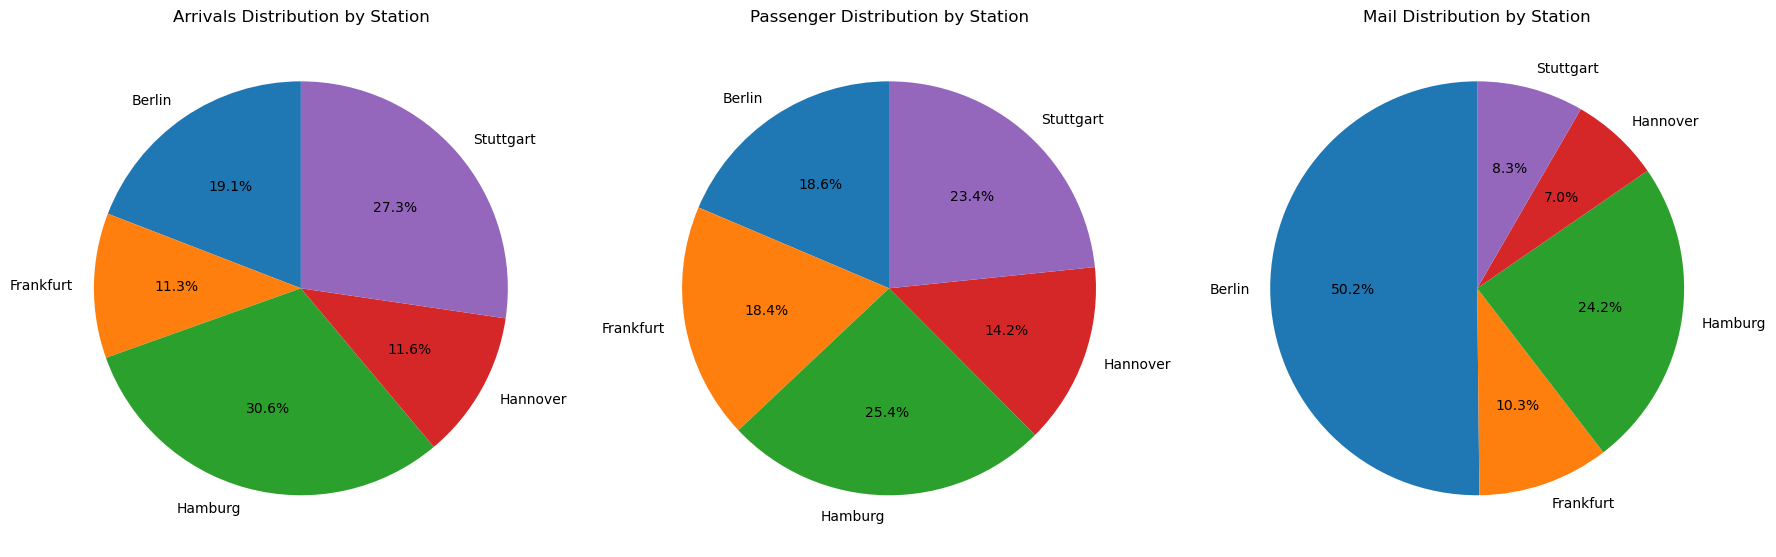

In [10]:
df = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')
required_columns = ['Station', 'Arrivals', 'Passengers', 'Mail']

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")
    
df['Arrivals'] = pd.to_numeric(df['Arrivals'], errors='coerce')
df['Passengers'] = pd.to_numeric(df['Passengers'], errors='coerce')
df['Mail'] = pd.to_numeric(df['Mail'], errors='coerce')

grouped = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum() # agrupar por estacao

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].pie(grouped['Arrivals'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Arrivals Distribution by Station')

axes[1].pie(grouped['Passengers'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Passenger Distribution by Station')

axes[2].pie(grouped['Mail'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[2].set_title('Mail Distribution by Station')

plt.tight_layout()
plt.show()

# US18 - Result Interpretation and Analysis

## Analysis and Interpretation of Results

In US18, the objective was to analyze how **train arrivals**, **passengers**, and **mail** are distributed across all stations using recorded data. This was accomplished through the creation of three pie charts, each representing one of the three elements. These charts allow for a clear visual comparison of each station's contribution to the overall activity of the railway network.

The results revealed key insights such as:

- **Train Arrivals:** Stations such as **Stuttgart** and **Hamburg** had the highest shares, suggesting their role as major hubs in the network.

- **Passenger Distribution:** A similar pattern was observed, with these same stations also responsible for transporting a large percentage of the network's passengers. Some stations, such as **Hannover**, had noticeably lower values.

- **Mail Distribution:** Mail volume had a significantly larger slice for **Berlin**, not showing any particular correlation with the other pie charts.

These visualizations provide an immediate overview of operational concentration, highlighting which stations have the greatest logistical significance and which ones may be underutilized.

---

## Extrapolation to the Project Context

In the context of the Integrative Project, these results have several important implications for both simulation design and strategic gameplay:

1. **Operational Prioritization:** Stations with high proportions of train arrivals and passengers (e.g., Hamburg) can be marked as priority nodes for investment in infrastructure or gameplay upgrades.

2. **Balancing and Optimization:** Stations with very low activity may be candidates for strategic development missions or optimization challenges within the game narrative.

3. **Gameplay Progression:** The data-driven analysis supports designing game progression mechanics such as unlocking advanced technologies or new lines after improving distribution balance across the network.

4. **Realism in Simulation:** Using actual traffic proportions to calibrate event frequency or operational difficulty ensures that the simulation reflects realistic complexity.

---

By presenting the data in an accessible and comparative format, this user story supports informed decision-making, strategic planning, and simulation realism — all goals of the Integrative Project.


# Distribuição Percentual entre Membros do Grupo

Abaixo está a divisão de 100% do trabalho entre os quatro integrantes do grupo:

- **1240934 – Francisco Vasconcelos**: 40%
- **1240935 – Gabriel Azevedo**: 20%
- **1240936 – Gonçalo Azevedo**: 20%
- **1240941 – Paulo Ferreira**: 20%

O quinto membro do grupo não compareceu/participou no projeto.